In [2]:
import sys
import json
import random
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import napari
from scipy.interpolate import griddata
from pathlib import Path

from plot_utils_era5 import *

project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(Path.cwd().parent / 'scripts'))

sys.path.append(f"{project_root}src/")
# Import utilities
from utilities import KernelNN, KernelNN_subgraph, GraphLMDBReader, setup_device, get_output_affinities
from plot_utilities import plot_results_napari, plot_results_matplotlib

sys.path.append(f"{project_root}/ERA5/scripts/")
from utilities_era5 import ERA5_Graph_Generator as Data_Generator
from utilities_era5 import ERA5_Graph_Generator_perSampleNorm as Data_Generator_old
data_path = project_root / 'ERA5' / 'data'

# Device setup
device = setup_device()
print(f'Using device: {device}')

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import subprocess


def load_model(id:str, model_type:str='random_crop'):
    model_path = project_root / 'ERA5' / 'trained_models' / model_type / f'{id}.pth'
    config_path = project_root / 'ERA5' / 'trained_models' / model_type / 'logs' / 'configs' / f'{id}.json' 
    
    with open(config_path, 'r') as f:
        config = json.load(f)
    
    model = KernelNN(
        width=config['width'],
        ker_width=config['ker_width'],
        depth=config['depth'],
        ker_in=config['edge_attr'],
        in_width=config['node_features'],
        out_width=config['out_width']
    ).to(device)
    
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    
    return model, config

Using device: mps


In [6]:
os.system("rsync -r springfield:~/new/NOFE/ERA5/trained_models/* ../trained_models/")

** WARNING: connection is not using a post-quantum key exchange algorithm.
** This session may be vulnerable to "store now, decrypt later" attacks.
** The server may need to be upgraded. See https://openssh.com/pq.html


0

In [7]:
# choose data
model_type = 'regular'


# ---------------------------------------------------------------------------
sys.path.append(f"{project_root}/ERA5/scripts/")
from utilities_era5 import ERA5_Graph_Generator as Data_Generator
from utilities_era5 import ERA5_Graph_Generator_perSampleNorm as Data_Generator_old



# Paths
trained_models_path = project_root / 'ERA5' / 'trained_models' / model_type
training_logs_path = trained_models_path / 'logs'
data_path = project_root.parent / 'ERA5' / 'data'  # Adjust if needed

print('Available models:\n')
files = sorted(os.listdir(trained_models_path), reverse=True)

for i, f in enumerate(files):
    if (Path(f).suffix == ".pth") and ('tkernel' in f):
        print(f'[{i}] {f}')


Available models:

[27] test1_model8_median_tkernel_wPos_2026-04-23_t16-12-31.pth
[29] test1_model7_median_tkernel_wPos_2026-04-23_t14-57-39.pth
[30] test1_model7_median_tkernel_2026-04-23_t06-20-49.pth
[33] test1_model6_median_tkernel_wPos_2026-04-23_t13-20-37.pth
[34] test1_model6_median_tkernel_2026-04-23_t00-37-33.pth
[36] test1_model5_median_tkernel_wPos_2026-04-23_t12-29-07.pth
[37] test1_model5_median_tkernel_wPos_2026-04-23_t11-54-44.pth
[38] test1_model5_median_tkernel_wPos_2026-04-23_t10-56-10.pth
[39] test1_model5_median_tkernel_wPos_2026-04-23_t10-14-53.pth
[40] test1_model5_median_tkernel_2026-04-22_t21-22-37.pth
[41] test1_model5_median_tkernel_2026-04-22_t18-36-43.pth
[44] test1_model4_median_tkernel_wPos_2026-04-23_t14-01-59.pth
[45] test1_model4_median_tkernel_2026-04-23_t04-10-13.pth
[49] test1_model3_median_tkernel_wPos_2026-04-23_t13-33-11.pth
[50] test1_model3_median_tkernel_wPos_2026-04-23_t12-19-20.pth
[51] test1_model3_median_tkernel_2026-04-23_t01-56-54.pth
[55

In [13]:
model_id = 'test1_model5_median_tkernel_2026-04-22_t21-22-37'
model, config = load_model(id=model_id , model_type='regular')
config

{'model_config_path': 'ERA5/configurations/regular/model_configs/testmodel5_w64_kw32_d3.json',
 'dataset_id': 'dataset_reg_fixcrop_median_woPos_tkernel',
 'dataset_path': 'ERA5/datasets/regular',
 'learning_rate': 1e-05,
 'scheduler_step': 5,
 'scheduler_gamma': 0.9,
 'epochs': 100,
 'random_seed': 42,
 'use_gradient_clipping': True,
 'track_gradients': True,
 'checkpoint_every': 5,
 'width': 64,
 'ker_width': 32,
 'depth': 3,
 'node_features': 11,
 'edge_attr': 7,
 'out_width': 3,
 'data_folder_path': '../data/',
 'dataset_save_path': '../datasets/regular/',
 'lat_min': 30,
 'lat_max': 75,
 'lon_min': -12,
 'lon_max': 33,
 'N_min': 500,
 'N_max': 10000,
 'k': 10,
 'perplexity': 10,
 'sampling_method': 'random',
 'train_date_start_end': ['2018-01-01', '2018-12-31'],
 'test_date_start_end': ['2019-01-01', '2019-01-31'],
 'train_samples_per_date': 10,
 'test_samples_per_date': 5,
 'feature_mode': 'channel_only',
 'sigma_method': 'global_median',
 'vars': ['w', 'v', 'z', 'q', 'r', 't', 'd

In [9]:
lat_min = config["lat_min"]
lat_max = config["lat_max"]
lon_min = config["lon_min"]
lon_max = config["lon_max"]
#N = config["N"]
k = config["k"]
perplexity = config["perplexity"]
sampling_method = config["sampling_method"]
train_date_start_end = config["train_date_start_end"]
test_date_start_end = config["test_date_start_end"]
train_samples_per_date = config["train_samples_per_date"]
test_samples_per_date = config["test_samples_per_date"]
feature_mode = config["feature_mode"]
vars = config["vars"]


In [12]:
model = KernelNN(
    width=config['width'],
    ker_width=config['ker_width'],
    depth=config['depth'],
    ker_in=config['edge_attr'],
    in_width=config['node_features'],
    out_width=config['out_width']
).to(device)

# Load trained weights
model_path = f'{trained_models_path}/{model_id}.pth'
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

print(f'Model loaded: {model_id}')
print(f'Total parameters: {sum(p.numel() for p in model.parameters()):,}')

Model loaded: test1_model5_median_tkernel_2026-04-22_t21-22-37
Total parameters: 141,603


In [18]:
dates = pd.date_range("2019-01-01", "2019-01-02").strftime("%Y-%m-%d").tolist()

bbox = lon_min, lat_min, lon_max, lat_max
#bbox = -12, 30, 33, 75
Generator = Data_Generator_old(data_path)

N=1000

data = []
data_locations = []

for date in dates:

    #Generator = Data_Generator(data_path)
    Generator.load_data(bbox=bbox, vars=vars, filename=f'{date}.nc')
    print(f'total points available: {Generator.da.shape[1]*Generator.da.shape[2]}')

    N=5000
    print('generate data')
    graph = Generator.sample_graph(N=N, k=k, perplexity=perplexity, sampling_method=sampling_method, gen_feature_mode=feature_mode, sigma_method=config['sigma_method'])
    sample = graph.to(device)
    data.append(sample)

total points available: 32761
generate data
total points available: 32761
generate data


In [15]:
def estimate_lipschitz_constant(batch, output, normalize=True):
    """
    Computes the Lipschitz estimate over graph edges: 
    max_ij ||g(x_i) - g(x_j)|| / ||f(x_i) - f(x_j)||

    Args:
        batch (torch_geometric.data.Data): Graph with attributes:
            - x: tensor (N, 12), original function values f(x)
            - edge_index: tensor (2, E), edge connections
        output (np.ndarray): array (N, 3), embedded function g(x)
        normalize (bool): whether to normalize f and g per feature before computing Lipschitz estimate

    Returns:
        lipschitz_estimate (np.ndarray): array of local Lipschitz ratios for each edge
    """
    device = batch.x.device
    f = batch.x                          # (N, 12)
    g = torch.tensor(output, device=device, dtype=f.dtype)  # (N, 3)
    edge_index = batch.edge_index       # (2, E)

    if normalize:
        # Normalize f per feature
        f_mean = f.mean(dim=0, keepdim=True)
        f_std = f.std(dim=0, unbiased=False, keepdim=True) + 1e-12
        f = (f - f_mean) / f_std

        # Normalize g per feature
        g_mean = g.mean(dim=0, keepdim=True)
        g_std = g.std(dim=0, unbiased=False, keepdim=True) + 1e-12
        g = (g - g_mean) / g_std

    i, j = edge_index[0], edge_index[1]  # indices for edges

    f_diff = f[i] - f[j]                # (E, 12)
    g_diff = g[i] - g[j]                # (E, 3)

    f_norms = torch.norm(f_diff, dim=1) + 1e-12   # (E,)
    g_norms = torch.norm(g_diff, dim=1)           # (E,)

    lipschitz_vals = g_norms / f_norms

    return lipschitz_vals.cpu().numpy()


In [20]:

normalize = True


model_out = []
pca_out = []
tsne_out = []
umap_out = []

lipschitz_model = []
lipschitz_pca = []
lipschitz_tsne = []
lipschitz_umap = []

for i in range(0, len(data)):
    batch = data[i]
    batch = batch.to(device)
    # NOFE
    output = model(batch.to(device)).detach().cpu().numpy()
    model_out.append(output)
    
    # switch to cpu
    X = sample.normed_values.detach().cpu().numpy()
    
    # PCA
    pca = PCA(n_components=3, copy=True, whiten=False, svd_solver='auto', tol=0.0, iterated_power='auto', n_oversamples=10, power_iteration_normalizer='auto', random_state=None)
    output = pca.fit_transform(X)
    pca_out.append(output)

    # TSNE
    tsne = TSNE(n_components=3, perplexity=perplexity, learning_rate=200, random_state=42)
    output = tsne.fit_transform(X)
    tsne_out.append(output)
    
    # UMAP
    umap_id = 'umap_buffer'
    dir = f'{project_root}/ERA5/umap'
    np.save(f'{dir}/{umap_id}.npy', X)
    subprocess.run(f"cd {dir} && conda run -n umap python execute_umap.py {umap_id}", shell=True)
    pred_umap = np.load(f'{dir}/res_{umap_id}.npy')
    umap_out.append(pred_umap)
    os.remove(f'{dir}/{umap_id}.npy')
    os.remove(f'{dir}/res_{umap_id}.npy')
    

/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/__init__.py:36: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")



importing libraries
reading in data
applying umap
saving file
"
file saved as res_umap_buffer.npy"

importing libraries
reading in data
applying umap
saving file
"
file saved as res_umap_buffer.npy"



/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/__init__.py:36: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")



In [21]:
normalize=True

lipschitz_nofe = []
lipschitz_pca = []
lipschitz_tsne = []
lipschitz_umap = []

for batch, output in zip(data, model_out):
    lip = estimate_lipschitz_constant(batch, output, normalize=normalize)
    lipschitz_nofe.append(lip)
for batch, output in zip(data, pca_out):
    lip = estimate_lipschitz_constant(batch, output, normalize=normalize)
    lipschitz_pca.append(lip)
for batch, output in zip(data, tsne_out):
    lip = estimate_lipschitz_constant(batch, output, normalize=normalize)
    lipschitz_tsne.append(lip)  
for batch, output in zip(data, umap_out):
    lip = estimate_lipschitz_constant(batch, output, normalize=normalize)
    lipschitz_umap.append(lip)  

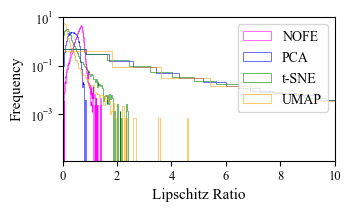

In [22]:
plt.rcParams.update({
    "font.family": "serif",                 # Use serif fonts
    "font.serif": ["Times New Roman"],      # Set to Times New Roman
    "font.size": 11,          # Base font size
    "axes.labelsize": 11,     # Axis labels
    "legend.fontsize": 10,    # Slightly smaller legend
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.loc": 'upper right',
    # Set font size in points
})

width = 1
ratio = 1.61803398875  # Golden ratio

linewidth = 3.31314 *1.1#* 2.54 # inch
width_in = width * linewidth  # = 5.85 inches
height_in = width_in / ratio # Choose a suitable aspect ratio, e.g., 3:2 or 4:3

lw = 0.4  # Line width for histograms
bins = 80

plt.figure(figsize= (width_in, height_in))

# Add label only for the first element in each loop
for idx, lip in enumerate(lipschitz_nofe):
    plt.hist(lip, bins=bins, histtype='step', density=True, color='magenta',
             label='NOFE' if idx == 0 else None,
             linewidth=lw)

for idx, lip in enumerate(lipschitz_pca):
    plt.hist(lip, bins=bins, histtype='step', density=True, color='blue',
             label='PCA' if idx == 0 else None,
             linewidth=lw)

for idx, lip in enumerate(lipschitz_tsne):
    plt.hist(lip, bins=bins, histtype='step', density=True, color='green',
             label='t-SNE' if idx == 0 else None,
             linewidth=lw)

for idx, lip in enumerate(lipschitz_umap):
    plt.hist(lip, bins=bins, histtype='step', density=True, color='orange',
             label='UMAP' if idx == 0 else None,
             linewidth=lw)

plt.yscale('log')
plt.xlim(0, 10)
plt.xlabel('Lipschitz Ratio')
plt.ylabel('Frequency')
plt.legend()

plt.gcf().set_size_inches(width_in, height_in)
plt.tight_layout()

#plt.savefig("/Users/laueb4818/github/overleaf/Neural_Operators_paper_draft/figures/lipschitz_plot.png", bbox_inches='tight', dpi=300)


plt.show()

/var/folders/sw/tjsbk4pj7q9gs_91lbj2_2rc0000gp/T/ipykernel_98037/2167926660.py:53: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


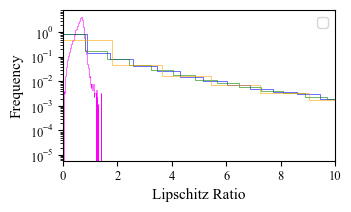

In [ ]:
lipschitz_nofe_all = np.concatenate(lipschitz_nofe)
lipschitz_pca_all = np.concatenate(lipschitz_pca)
lipschitz_tsne_all = np.concatenate(lipschitz_tsne)
lipschitz_umap_all = np.concatenate(lipschitz_umap)

plt.rcParams.update({
    "font.family": "serif",                 # Use serif fonts
    "font.serif": ["Times New Roman"],      # Set to Times New Roman
    "font.size": 11,          # Base font size
    "axes.labelsize": 11,     # Axis labels
    "legend.fontsize": 10,    # Slightly smaller legend
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.loc": 'upper right',
    # Set font size in points
})

width = 1
ratio = 1.61803398875  # Golden ratio

linewidth = 3.31314 *1.1#* 2.54 # inch
width_in = width * linewidth  # = 5.85 inches
height_in = width_in / ratio # Choose a suitable aspect ratio, e.g., 3:2 or 4:3

lw = 0.4  # Line width for histograms
bins = 80

plt.figure(figsize= (width_in, height_in))

# Add label only for the first element in each loop
plt.hist(lipschitz_nofe_all, bins=bins, histtype='step', density=True, color='magenta',
            label='NOFE' if idx == 0 else None,
            linewidth=lw)

plt.hist(lipschitz_pca_all, bins=bins, histtype='step', density=True, color='blue',
            label='PCA' if idx == 0 else None,
            linewidth=lw)


plt.hist(lipschitz_tsne_all, bins=bins, histtype='step', density=True, color='green',
            label='t-SNE' if idx == 0 else None,
            linewidth=lw)


plt.hist(lipschitz_umap_all, bins=bins, histtype='step', density=True, color='orange',
            label='UMAP' if idx == 0 else None,
            linewidth=lw)

plt.yscale('log')
plt.xlim(0, 10)
plt.xlabel('Lipschitz Ratio')
plt.ylabel('Frequency')
plt.legend()

plt.gcf().set_size_inches(width_in, height_in)
plt.tight_layout()

#plt.savefig("/Users/laueb4818/github/overleaf/Neural_Operators_paper_draft/figures/lipschitz_plot.png", bbox_inches='tight', dpi=300)


plt.show()

In [23]:
def mean1(data:list):
    means = []
    for d in data:
        means.append(np.mean(d))
    return np.mean(means)

def mean2(data:list):
    full_data = data[0]
    for d in range(1,len(data)):
        full_data = np.concatenate((full_data, data[d]), axis=0)
    return np.mean(full_data)

def var1(data:list):
    vars = []
    for d in data:
        vars.append(np.var(d))
    return np.mean(vars)

def var2(data:list):
    full_data = data[0]
    for d in range(1,len(data)):
        full_data = np.concatenate((full_data, data[d]), axis=0)
    return np.var(full_data)

In [24]:
print('Mean method 1 (mean of means):')
print(f'NOFE: {mean1(lipschitz_model)}')
print(f'PCA: {mean1(lipschitz_pca)}')
print(f't-SNE: {mean1(lipschitz_tsne)}')
print(f'UMAP: {mean1(lipschitz_umap)}') 

print('\nMean method 2 (mean of full data):')
print(f'NOFE: {mean2(lipschitz_model)}')
print(f'PCA: {mean2(lipschitz_pca)}')
print(f't-SNE: {mean2(lipschitz_tsne)}')
print(f'UMAP: {mean2(lipschitz_umap)}')

print('Variance method 1 (mean of variances):')
print(f'NOFE: {var1(lipschitz_model)}')
print(f'PCA: {var1(lipschitz_pca)}')
print(f't-SNE: {var1(lipschitz_tsne)}')
print(f'UMAP: {var1(lipschitz_umap)}')

print('\nVariance method 2 (variance of full data):')
print(f'NOFE: {var2(lipschitz_model)}')
print(f'PCA: {var2(lipschitz_pca)}')
print(f't-SNE: {var2(lipschitz_tsne)}')
print(f'UMAP: {var2(lipschitz_umap)}')

Mean method 1 (mean of means):
NOFE: 0.5834063291549683
PCA: 0.3394131064414978
t-SNE: 0.2973012328147888
UMAP: 3.26491117477417

Mean method 2 (mean of full data):
NOFE: 0.5834064483642578
PCA: 0.33941298723220825
t-SNE: 0.2973012626171112
UMAP: 3.2649102210998535
Variance method 1 (mean of variances):
NOFE: 0.029915153980255127
PCA: 0.018716761842370033
t-SNE: 0.055770691484212875
UMAP: 15.142167091369629

Variance method 2 (variance of full data):
NOFE: 0.03006364405155182
PCA: 0.019191760569810867
t-SNE: 0.055965084582567215
UMAP: 15.151357650756836


In [26]:
np.median(lipschitz_model_all), np.median(lipschitz_pca_all), np.median(lipschitz_tsne_all), np.median(lipschitz_umap_all)

(0.57859737, 0.33214507, 0.23807484, 2.1355124)

{'whiskers': [<matplotlib.lines.Line2D at 0x397f99c10>,
 'caps': [<matplotlib.lines.Line2D at 0x397faa190>,
 'boxes': [<matplotlib.lines.Line2D at 0x397f99970>,
 'medians': [<matplotlib.lines.Line2D at 0x397faa6d0>,
 'fliers': [<matplotlib.lines.Line2D at 0x397faa970>,
 'means': []}

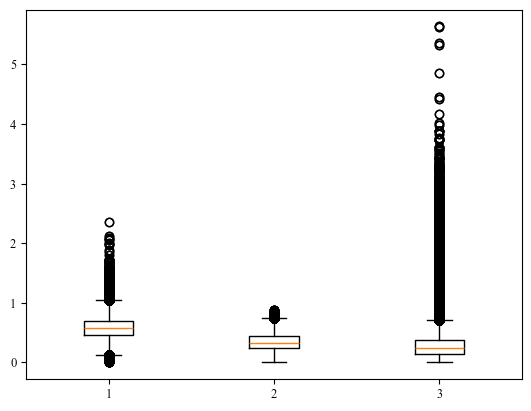

In [32]:
plt.boxplot([lipschitz_model_all,lipschitz_pca_all,lipschitz_tsne_all])